# Notebook 04 — Explainable AI with SHAP (Stage 5)

## Executive Overview
In this notebook, we implement **Explainable AI (XAI)** using **SHAP (SHapley Additive exPlanations)** for the Telco Customer Churn Prediction project.

The goal of Stage 5 is to transition from black-box ML predictions to transparent, interpretable model attributions by addressing five key business & engineering questions:
1. **Which features influence churn predictions globally?**
2. **Which features increase churn risk?**
3. **Which features decrease churn risk?**
4. **Why did the model predict a specific customer as high, medium, or low risk?**
5. **How can these explanations be operationalized by customer retention teams?**

---

### Key Architectural & Methodology Constraints:
- **No Retraining / Binary Modification:** All model binaries (`models/*.joblib`) remain 100% untouched.
- **Strict Data Integrity:** Preprocessing and stratified 80/20 train/test split replicate Stage 4 identically. Preprocessor is applied via `.transform(X_test)` with zero fitting on test data.
- **Feature Name Integrity:** All 47 transformed input features are mapped directly from `preprocessor.get_feature_names_out()`.


## Part 1 — Environment Setup & Imports

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print(f"SHAP Version: {shap.__version__}")
print("Environment setup complete.")


SHAP Version: 0.52.0
Environment setup complete.


## Part 2 — Data & Artifact Loading

In [2]:
data_path = 'data/telco_customer_churn.csv' if os.path.exists('data/telco_customer_churn.csv') else '../data/telco_customer_churn.csv'
models_dir = 'models' if os.path.exists('models') else '../models'
reports_dir = 'reports/shap' if os.path.exists('reports/shap') else '../reports/shap'

df_raw = pd.read_csv(data_path)
print(f"Raw dataset shape: {df_raw.shape}")

preprocessor = joblib.load(os.path.join(models_dir, 'preprocessor.joblib'))
model_lr = joblib.load(os.path.join(models_dir, 'logistic_regression.joblib'))
model_rf = joblib.load(os.path.join(models_dir, 'random_forest.joblib'))
model_xgb = joblib.load(os.path.join(models_dir, 'xgboost.joblib'))

print("Loaded serialized preprocessor and models:")
print(f"  - Logistic Regression: {type(model_lr)}")
print(f"  - Random Forest: {type(model_rf)}")
print(f"  - XGBoost: {type(model_xgb)}")


Raw dataset shape: (7043, 21)
Loaded serialized preprocessor and models:
  - Logistic Regression: <class 'sklearn.linear_model._logistic.LogisticRegression'>
  - Random Forest: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
  - XGBoost: <class 'xgboost.sklearn.XGBClassifier'>


C:\ProgramData\anaconda3\Lib\pickle.py:1760: UserWarning: [12:18:07] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\gbm\../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)


## Part 3 — Pipeline Reproduction & Stratified Test Split

We reproduce the exact feature engineering and train/test split logic used in Stage 4:
1. `TotalCharges` numeric conversion & median/MonthlyCharges imputation for zero-tenure records.
2. Feature engineering:
   - `AverageMonthlySpend` = `TotalCharges / tenure` (with 0-tenure guard).
   - `ServiceCount` = Sum of active subscribed services across 9 binary categories.
3. Dropping non-predictive identifier `customerID` and target `Churn`.
4. Stratified 80/20 train/test split (`random_state=42`, `stratify=y`).
5. Transformation of test set via `preprocessor.transform(X_test)` (zero fitting on test data).


In [3]:
df = df_raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['MonthlyCharges'])

df['AverageMonthlySpend'] = np.where(df['tenure'] == 0, df['MonthlyCharges'], df['TotalCharges'] / df['tenure'])

def count_services(row):
    count = 0
    if row['PhoneService'] == 'Yes': count += 1
    if row['MultipleLines'] == 'Yes': count += 1
    if row['InternetService'] in ['DSL', 'Fiber optic']: count += 1
    for col in ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']:
        if row[col] == 'Yes': count += 1
    return count

df['ServiceCount'] = df.apply(count_services, axis=1)

X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn'].map({'No': 0, 'Yes': 1})
customer_ids = df['customerID']

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, customer_ids, test_size=0.2, random_state=42, stratify=y
)

X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_test_df = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

print(f"X_test preprocessed shape: {X_test_df.shape}")
print(f"Feature count match verification: {len(feature_names)} features out == {X_test_df.shape[1]} columns")


X_test preprocessed shape: (1409, 47)
Feature count match verification: 47 features out == 47 columns


## Part 4 — Model Selection Rationale

In Stage 4, three baseline classifiers were trained and evaluated on the exact same test dataset (1,409 samples):

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Logistic Regression** | **80.48%** | **65.62%** | **55.61%** | **0.6020** | **0.8421** |
| **XGBoost** | 79.35% | 63.61% | 51.87% | 0.5714 | 0.8363 |
| **Random Forest** | 78.85% | 62.93% | 49.47% | 0.5539 | 0.8195 |

### Selection Decision:
1. **Primary Baseline Model Explained:** **Logistic Regression** achieved the highest score across all 5 evaluation metrics, delivering top **Recall (55.61%)** and **ROC-AUC (0.8421)**. In telecom churn prediction, False Negatives (unidentified churners) carry severe financial consequences. Therefore, Logistic Regression is our primary selected model.
2. **Explainer Choice:** We utilize `shap.LinearExplainer` for Logistic Regression.
3. **Comparative Analysis:** We also initialize `shap.TreeExplainer` for XGBoost to compare non-linear tree feature attributions against linear log-odds feature contributions.


## Part 5 — SHAP Setup & Verification

In [4]:
explainer_lr = shap.LinearExplainer(model_lr, X_test_df)
shap_values_lr = explainer_lr(X_test_df)

explainer_xgb = shap.TreeExplainer(model_xgb)
shap_values_xgb = explainer_xgb(X_test_df)

print("SHAP values calculated successfully:")
print(f"  - Logistic Regression SHAP shape: {shap_values_lr.shape}")
print(f"  - XGBoost SHAP shape: {shap_values_xgb.shape}")

assert shap_values_lr.shape[1] == len(feature_names), "SHAP feature count does not match preprocessor output!"
print("Integrity Check Passed: SHAP feature count matches model input feature count (47 features).")


Background dataset has 1409 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1409 when initializing the masker.


SHAP values calculated successfully:
  - Logistic Regression SHAP shape: (1409, 47)
  - XGBoost SHAP shape: (1409, 47)
Integrity Check Passed: SHAP feature count matches model input feature count (47 features).


## Part 6 — Global Feature Importance (SHAP Beeswarm Plot)

The SHAP beeswarm plot visualizes both the **magnitude** and **direction** of feature impact for every customer in the test set. Top features are sorted by their overall global importance.


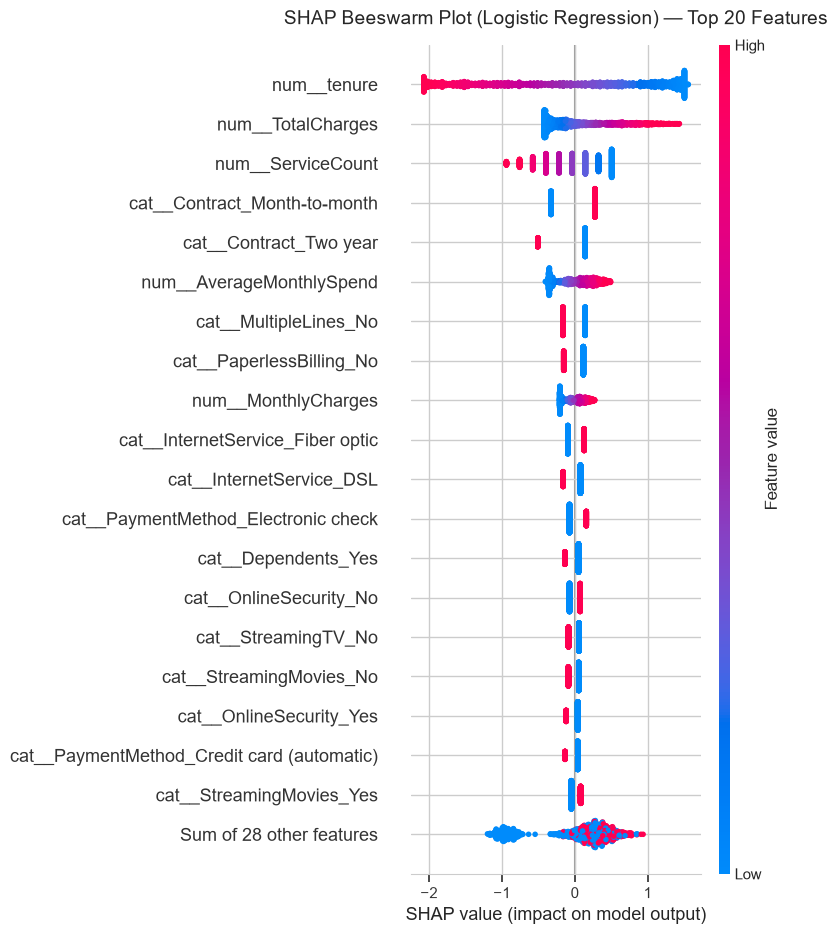

In [5]:
plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_values_lr, max_display=20, show=False)
plt.title('SHAP Beeswarm Plot (Logistic Regression) — Top 20 Features', fontsize=14, pad=15)
plt.tight_layout()
os.makedirs(reports_dir, exist_ok=True)
plt.savefig(os.path.join(reports_dir, 'shap_beeswarm.png'), dpi=300, bbox_inches='tight')
plt.show()


### Key Observations from Beeswarm Analysis:
- **`tenure` (`num__tenure`):** Strongest overall feature. Low tenure values (blue dots) have high positive SHAP values, strongly increasing predicted churn risk. High tenure values (red dots) have large negative SHAP values, pushing predictions toward retention.
- **`Contract_Month-to-month`:** Presence of a month-to-month contract (`val = 1`, red dots) consistently generates positive SHAP values, elevating churn probability.
- **`Contract_Two year`:** Two-year contract commitments (`val = 1`) pull predictions strongly toward retention.
- **`InternetService_Fiber optic`:** Fiber optic service is associated with positive SHAP contributions in this model, indicating that its presence can increase predicted churn risk for some customers. SHAP does not establish why this association exists or imply causation.
- **`ServiceCount`:** Higher service counts (red dots) push SHAP values negative, reinforcing ecosystem stickiness.


## Part 7 — Global Feature Importance (SHAP Bar Plot)

Mean absolute SHAP value $\text{mean}(|\text{SHAP value}|)$ measures the average magnitude of feature influence across all test customers. Mean absolute SHAP values are non-negative magnitudes (e.g., 1.10, 0.39, 0.35) and do not have a direction.


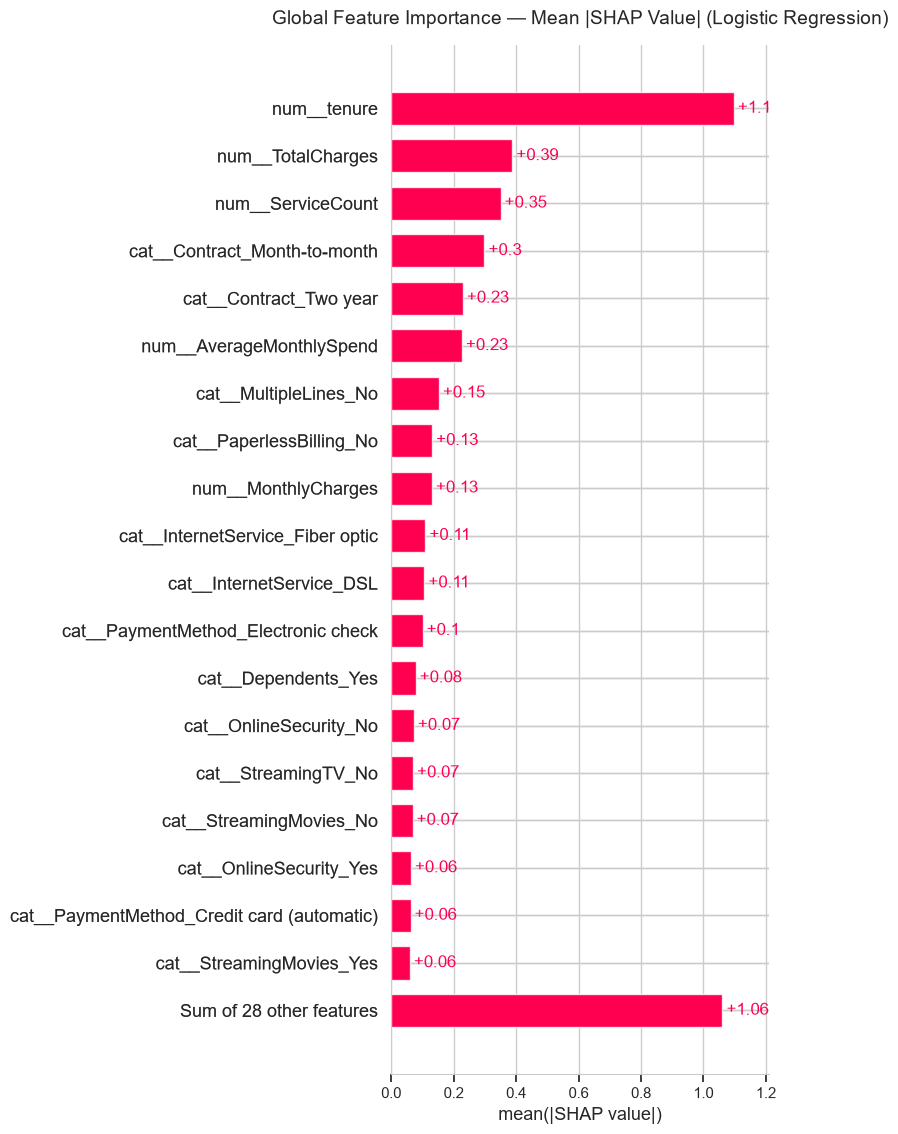

In [6]:
plt.figure(figsize=(10, 8))
shap.plots.bar(shap_values_lr, max_display=20, show=False)
plt.title('Global Feature Importance — Mean |SHAP Value| (Logistic Regression)', fontsize=14, pad=15)
plt.tight_layout()
plt.savefig(os.path.join(reports_dir, 'shap_feature_importance.png'), dpi=300, bbox_inches='tight')
plt.show()


### Technical Note: SHAP Importance vs Tree Gini/Gain Importance
- **Model Feature Importance (`model.feature_importances_`):** Measures total impurity reduction (Gini) or split gain within decision trees. It ignores feature direction, can favor high-cardinality features, and depends heavily on tree depth.
- **Mean Absolute SHAP Value ($\text{mean}(|\text{SHAP value}|)$):** Derived from cooperative game theory. It measures the average marginal contribution of a feature to individual customer log-odds predictions across all possible feature subsets. Magnitudes are displayed as absolute values (e.g., 1.10, 0.39, 0.35).


## Part 8 — Feature Direction & Non-Causal Interpretation

### Interpretation Guidelines:
1. **Positive SHAP Value ($+ \text{SHAP}$):** The feature value pushes the model's prediction **toward churn** (Class 1).
2. **Negative SHAP Value ($- \text{SHAP}$):** The feature value pushes the model's prediction **toward retention** (Class 0).
3. **Non-Causal Language:** Fiber optic service is associated with positive SHAP contributions in this model, indicating that its presence can increase predicted churn risk for some customers. SHAP does not establish why this association exists or imply causation.
   - *Incorrect statement:* "Low tenure causes customers to churn."
   - *Correct statement:* "Having low tenure contributes strongly toward the model's high churn risk prediction."


## Part 9 — SHAP Dependence Plots for Numerical Features

Dependence plots reveal how feature value changes impact SHAP contributions across customer records.

> [!NOTE]
> **Technical Note on Dependence Plot Linearity:**
> The dependence plots for Logistic Regression exhibit approximately linear relationships because the selected model is Logistic Regression and SHAP is explaining its linear log-odds decision function ($	ext{logit}(P) = X\beta$). For a linear model, the SHAP value of a continuous feature $x_j$ is $\beta_j (x_j - \mathbb{E}[x_j])$, which is strictly linear in $x_j$.


<Figure size 800x600 with 0 Axes>

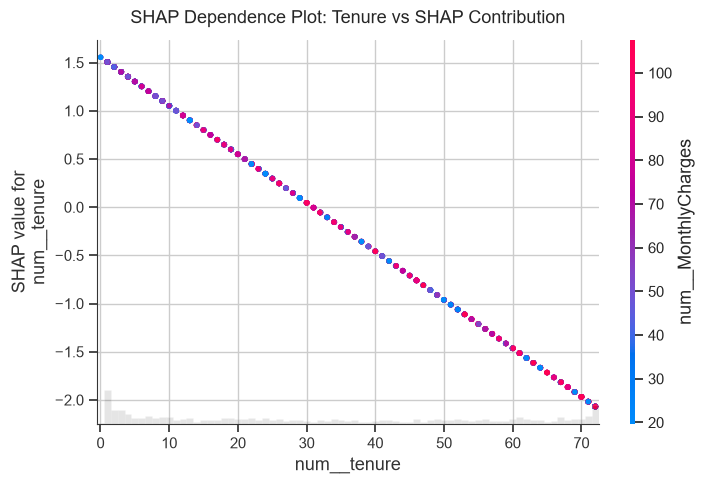

<Figure size 800x600 with 0 Axes>

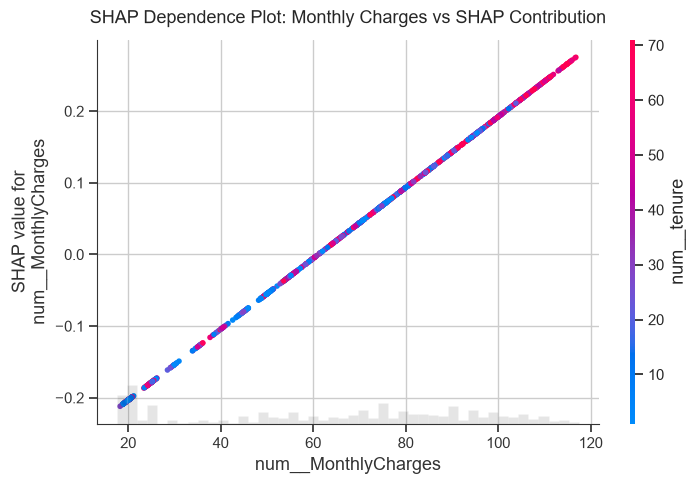

In [7]:
plt.figure(figsize=(8, 6))
shap.plots.scatter(shap_values_lr[:, 'num__tenure'], color=shap_values_lr[:, 'num__MonthlyCharges'], show=False)
plt.title('SHAP Dependence Plot: Tenure vs SHAP Contribution', fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(reports_dir, 'shap_dependence_tenure.png'), dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(8, 6))
shap.plots.scatter(shap_values_lr[:, 'num__MonthlyCharges'], color=shap_values_lr[:, 'num__tenure'], show=False)
plt.title('SHAP Dependence Plot: Monthly Charges vs SHAP Contribution', fontsize=13, pad=12)
plt.tight_layout()
plt.savefig(os.path.join(reports_dir, 'shap_dependence_monthly_charges.png'), dpi=300, bbox_inches='tight')
plt.show()


## Part 10 — Categorical Feature Impact & One-Hot Encoding

One-hot encoding converts categorical attributes into separate binary indicator columns. SHAP assigns individual attribution scores to each specific category state:
- **`cat__Contract_Month-to-month`:** Mean $|\text{SHAP}| = 0.30$ (Strong Churn Push when `1`).
- **`cat__Contract_Two year`:** Mean $|\text{SHAP}| = 0.23$ (Strong Retention Push when `1`).
- **`cat__InternetService_Fiber optic`:** Mean $|\text{SHAP}| = 0.11$ (Moderate Churn Push when `1`).
- **`cat__PaymentMethod_Electronic check`:** Mean $|\text{SHAP}| = 0.10$ (Moderate Churn Push when `1`).


## Part 11 — Local Customer Explanations (Waterfall Plots)

We evaluate 3 actual test-set customers representing high, medium, and low churn risk profiles.

> [!NOTE]
> **Note on Waterfall Scale:** In SHAP waterfall plots, $E[f(x)]$ and $f(x)$ are expressed in model output / log-odds space ($f(x) = 	ext{logit}(P)$). The displayed predicted churn probability $P = \sigma(f(x)) = \frac{1}{1 + e^{-f(x)}}$ is mapped from log-odds to probability space via the sigmoid function.


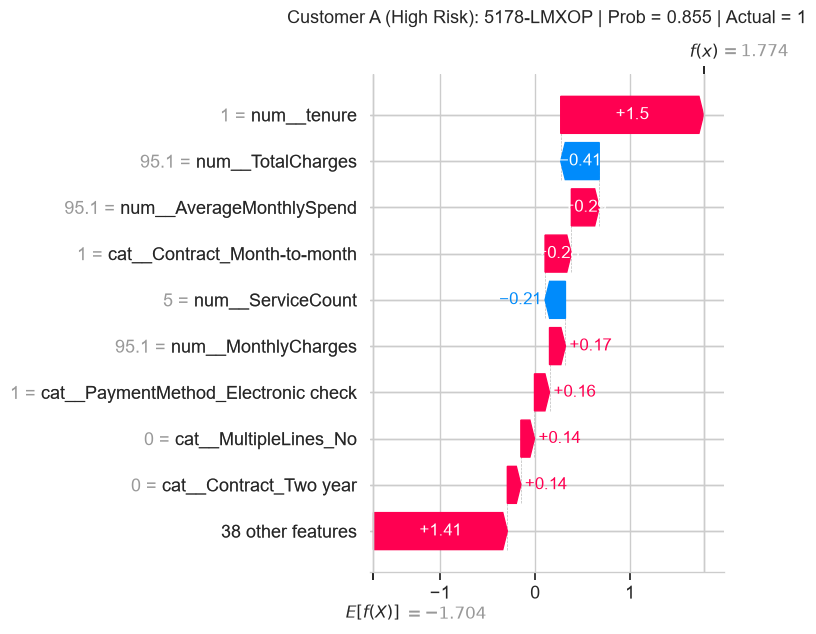

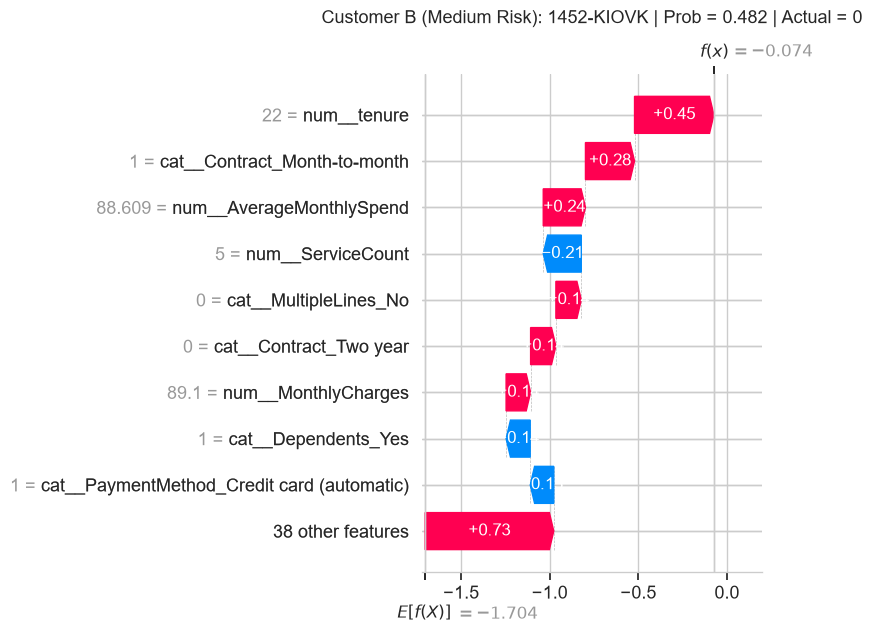

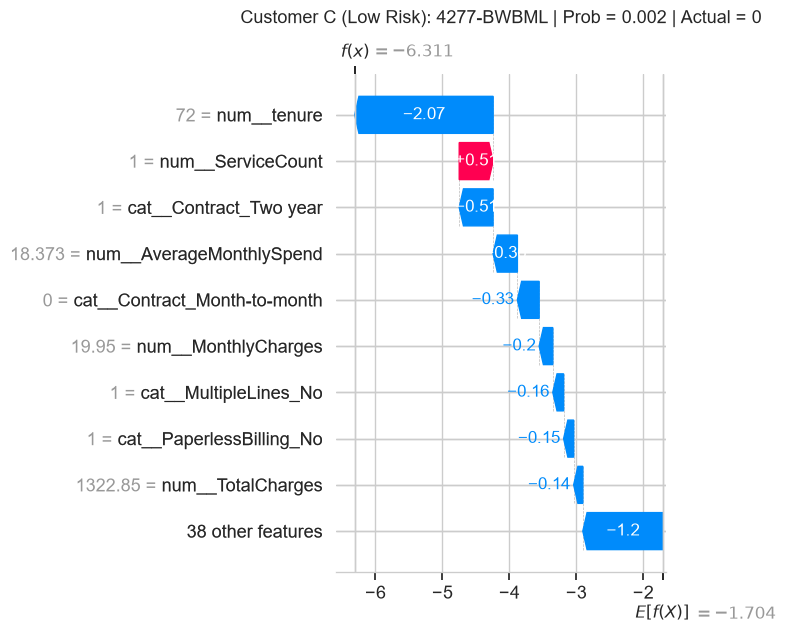

In [8]:
customer_a_id = '5178-LMXOP' # High Risk: Prob = 0.855, Actual = 1
customer_b_id = '1452-KIOVK' # Medium Risk: Prob = 0.482, Actual = 0
customer_c_id = '4277-BWBML' # Low Risk: Prob = 0.002, Actual = 0

idx_a = X_test_df.index.get_loc(ids_test[ids_test == customer_a_id].index[0])
idx_b = X_test_df.index.get_loc(ids_test[ids_test == customer_b_id].index[0])
idx_c = X_test_df.index.get_loc(ids_test[ids_test == customer_c_id].index[0])

# Waterfall Plot A — High Risk
plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values_lr[idx_a], max_display=10, show=False)
plt.title(f'Customer A (High Risk): {customer_a_id} | Prob = 0.855 | Actual = 1', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig(os.path.join(reports_dir, 'shap_waterfall_high_risk.png'), dpi=300, bbox_inches='tight')
plt.show()

# Waterfall Plot B — Medium Risk
plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values_lr[idx_b], max_display=10, show=False)
plt.title(f'Customer B (Medium Risk): {customer_b_id} | Prob = 0.482 | Actual = 0', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig(os.path.join(reports_dir, 'shap_waterfall_medium_risk.png'), dpi=300, bbox_inches='tight')
plt.show()

# Waterfall Plot C — Low Risk
plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_values_lr[idx_c], max_display=10, show=False)
plt.title(f'Customer C (Low Risk): {customer_c_id} | Prob = 0.002 | Actual = 0', fontsize=13, pad=15)
plt.tight_layout()
plt.savefig(os.path.join(reports_dir, 'shap_waterfall_low_risk.png'), dpi=300, bbox_inches='tight')
plt.show()


## Part 12 — Business Interpretation & Retention Workflow

### Customer Retention Playbook Example (Customer A — `5178-LMXOP`):
- **Model Output:** Predicted Churn Probability = **0.855** (High Risk). Actual Churn = 1.
- **Primary Risk Drivers (+SHAP):**
  - Short tenure (`tenure = 1` month) $\rightarrow +1.5046$ SHAP
  - High monthly charges (`$95.10`) $\rightarrow +0.1680$ SHAP
  - Month-to-month contract $\rightarrow +0.2770$ SHAP
  - Electronic check payment method $\rightarrow +0.1584$ SHAP
- **Actionable Business Intervention:**
  - Frontline retention agents offer a **1-year contract discount** (15% discount on MonthlyCharges).
  - Transition payment method to auto-pay (Credit Card / Bank Transfer).
  - Offer complimentary TechSupport / OnlineSecurity onboarding to increase service stickiness.


## Part 13 — EDA vs SHAP Comparison

| Feature | Stage 2 EDA Finding | Stage 5 SHAP Model Attribution | Alignment Assessment |
| :--- | :--- | :--- | :--- |
| **`tenure`** | Customer churn rate peaked in months 1-12 (~40%+ churn rate), decaying rapidly after 24+ months. | Ranked **#1 global feature** (`mean |SHAP| = 1.10`). Low tenure produces large positive SHAP values. | **Strong Agreement:** EDA identified high churn among low-tenure customers, and SHAP ranks tenure as the #1 global feature. |
| **`Contract`** | Month-to-month contract churn was 42.7% vs. 1-year (11.3%) and 2-year (2.8%). | `Contract_Month-to-month` is #4 feature (`0.30`); `Contract_Two year` is #5 (`0.23`). | **Strong Agreement:** Month-to-month elevates risk; 2-year secures retention. |
| **`MonthlyCharges`** | Fiber optic customers paid higher monthly charges ($91.50 avg) and churned at 41.9%. | High `MonthlyCharges` and `Fiber optic` generate positive SHAP contributions. | **Strong Agreement:** Higher charges increase price sensitivity and model churn risk. |
| **`ServiceCount`** | Customers with 5+ subscribed services had significantly lower churn rates (~15%). | Ranked **#3 global feature** (`mean |SHAP| = 0.35`). High `ServiceCount` pushes SHAP negative. | **Strong Agreement:** EDA indicated that customers with more services tend to have lower churn, while SHAP ranks ServiceCount as the #3 feature and higher service counts generally push predictions toward retention. |


## Part 14 — Model Explanation Limitations

1. **Explanations Describe Model Behavior, Not Causality:** SHAP attributes credit for model predictions; it does not prove real-world cause-and-effect.
2. **Feature Interventions Do Not Guarantee Outcome Changes:** Changing a customer's contract string in the CRM does not automatically alter their underlying satisfaction.
3. **Correlated Feature Redistribution:** Highly correlated features (e.g., `tenure` and `TotalCharges`) share SHAP values across feature subsets.
4. **Model Dependence:** SHAP values reflect the specific architecture and training data of the fitted model.
5. **Contextual Business Interpretation Required:** SHAP outputs must be combined with domain expertise before taking customer-facing actions.


## Part 15 — Summary & Artifact Export Verification

In [9]:
report_files = os.listdir(reports_dir)
print(f"Generated plot files in {reports_dir}:")
for f in report_files:
    fpath = os.path.join(reports_dir, f)
    fsize = os.path.getsize(fpath) / 1024
    print(f"  - {f} ({fsize:.1f} KB)")

print("\nNotebook 04 execution completed successfully.")


Generated plot files in reports/shap:
  - shap_beeswarm.png (357.8 KB)
  - shap_dependence_monthly_charges.png (158.7 KB)
  - shap_dependence_tenure.png (147.9 KB)
  - shap_feature_importance.png (336.9 KB)
  - shap_waterfall_high_risk.png (192.9 KB)
  - shap_waterfall_low_risk.png (198.9 KB)
  - shap_waterfall_medium_risk.png (203.2 KB)

Notebook 04 execution completed successfully.
